In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter

formatter = ScalarFormatter(useMathText=True)
formatter.set_powerlimits((0, 0))

%config InlineBackend.figure_format = 'retina'
cmap = plt.cm.viridis
cmap2 = plt.cm.twilight
rng = np.random.default_rng(seed=12345)   # PCG64 by default
cm = 1 / 2.54

# Hippocampal Data

### Load data


In [9]:
n_channels = 31
fs = 1250 # Hz

path = '../Hippocampal/data/'
file = 'ec013.527.eeg'
x = np.fromfile(path+file, dtype=np.int16)
x = x.reshape(-1, n_channels)

signal = x[:,5]      # sixth channel
time = np.arange(len(signal))/fs
print(time.shape[0])

1325125


### Plot dense data

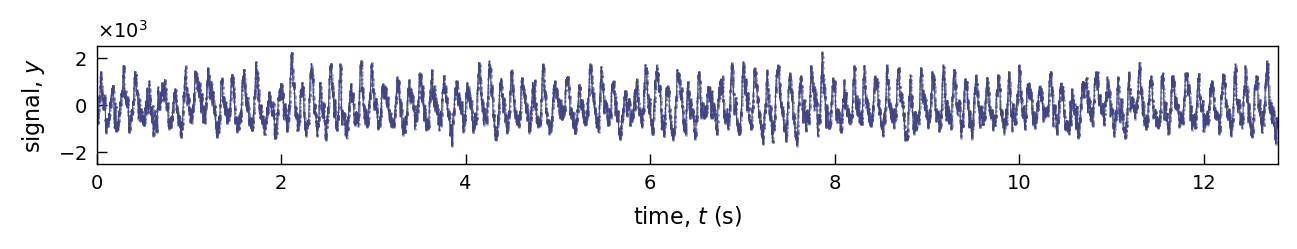

In [8]:
imin = 10000
istep = 1
Nmax = 16000
imax = imin + istep*Nmax

tk = time[imin:imax:istep] - time[imin]
yk = signal[imin:imax:istep]
dtmin = np.diff(tk).mean()

# fixed axis geometry
ax_h = 1.5 * cm
ax_w = 15 * cm

left = 1.5 * cm
bottom = 1.5 * cm
right = 0.5 * cm
top = 0.5 * cm

fig_w = left + ax_w + right
fig_h = bottom + ax_h + top

fig = plt.figure(figsize=(fig_w, fig_h))

ax = fig.add_axes([
    left / fig_w,
    bottom / fig_h,
    ax_w / fig_w,
    ax_h / fig_h
])

ax.plot(tk, yk,  '-', c=cmap(0.2), lw=0.4)
ax.plot(tk, yk,  '.', alpha=0.5, c=cmap(0.2), mew=0, ms=2)
ax.set_xlim(tk[0], tk[-1])
ax.set_ylim(-2500, 2500)
ax.yaxis.set_major_formatter(formatter)
ax.yaxis.get_offset_text().set_fontsize(7)

ax.set_xlabel('time, $t$ (s)', fontsize=8)
ax.set_ylabel('signal, $y$', fontsize=8)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/HippocampalTrace.pdf')

# FFT Analysis

Subtract the sample mean to remove the zero-frequency offset, then compute the one-sided FFT and its power spectral density.

In [10]:
centered_signal = yk.astype(float) - yk.mean()
sampling_frequency = 1 / dtmin
fft_values = np.fft.rfft(centered_signal)
frequencies = np.fft.rfftfreq(centered_signal.size, d=dtmin)

# One-sided power spectral density (signal units squared per Hz).
power_spectrum = np.abs(fft_values) ** 2 / (sampling_frequency * centered_signal.size)
power_spectrum[1:-1] *= 2

peak_index = 1 + np.argmax(power_spectrum[1:])
peak_frequency = frequencies[peak_index]
print(f'Dominant nonzero frequency: {peak_frequency:.3f} Hz')

Dominant nonzero frequency: 8.359 Hz


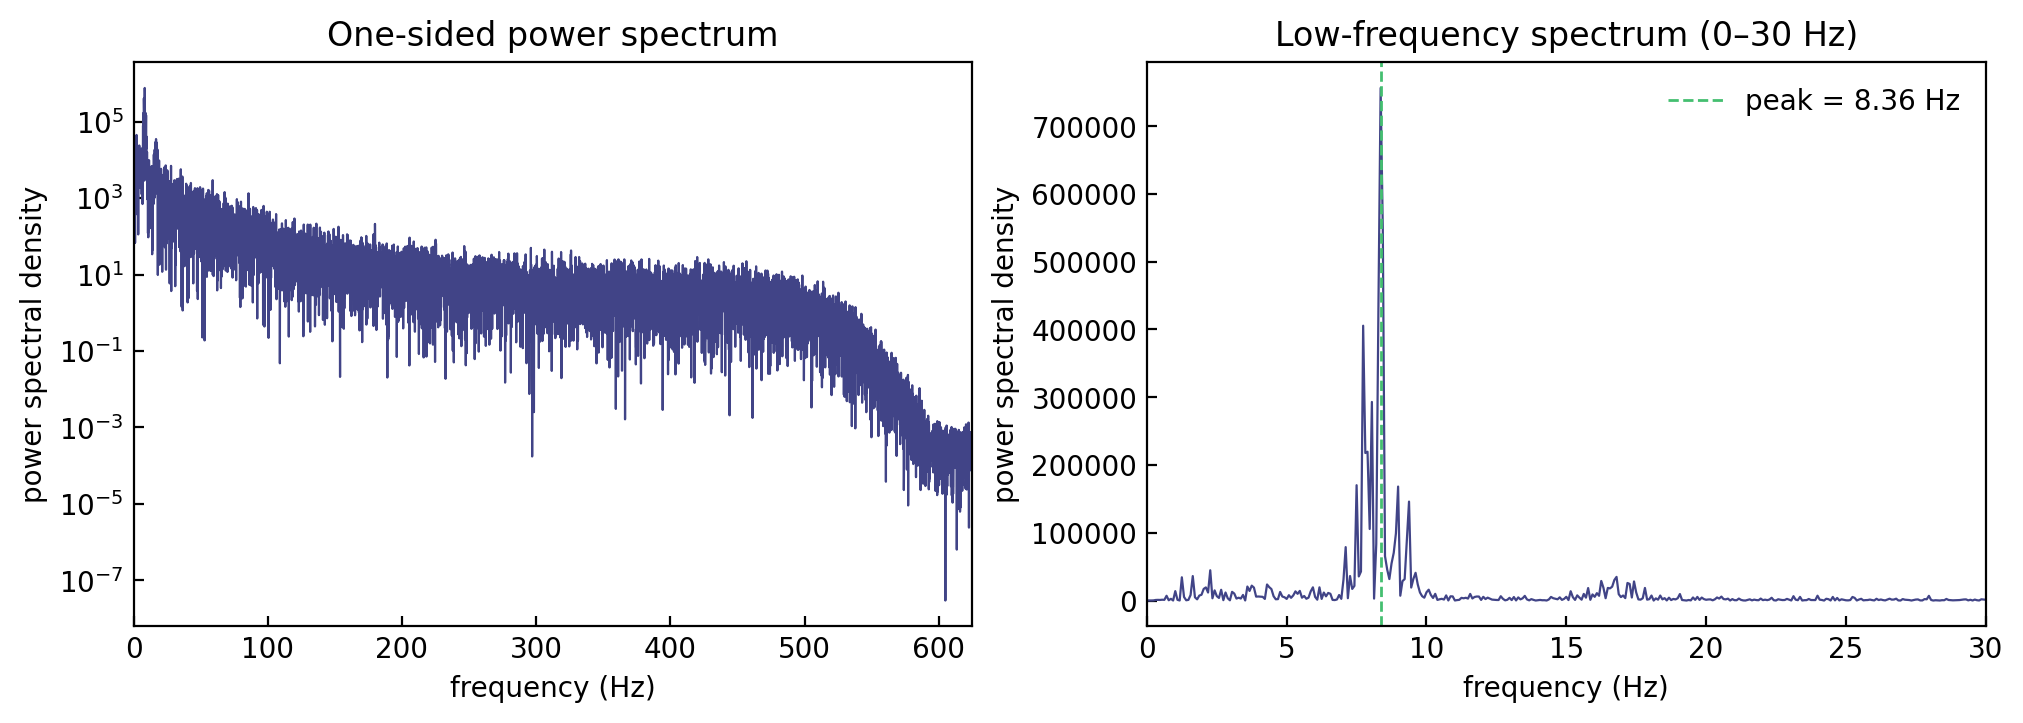

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)

axes[0].semilogy(frequencies[1:], power_spectrum[1:], color=cmap(0.2), lw=0.8)
axes[0].set(
    xlabel='frequency (Hz)',
    ylabel='power spectral density',
    title='One-sided power spectrum',
    xlim=(0, sampling_frequency / 2),
)

max_frequency = 30.0
frequency_mask = (frequencies > 0) & (frequencies <= max_frequency)
axes[1].plot(
    frequencies[frequency_mask],
    power_spectrum[frequency_mask],
    color=cmap(0.2),
    lw=0.8,
)
axes[1].axvline(
    peak_frequency,
    color=cmap(0.7),
    ls='--',
    lw=1,
    label=f'peak = {peak_frequency:.2f} Hz',
)
axes[1].set(
    xlabel='frequency (Hz)',
    ylabel='power spectral density',
    title=f'Low-frequency spectrum (0–{max_frequency:g} Hz)',
    xlim=(0, max_frequency),
)
axes[1].legend(frameon=False)

for ax in axes:
    ax.tick_params(direction='in')

plt.show()

## Harmonic fit

Treat the FFT peak as the point estimate $\hat\omega=2\pi\hat f$. At this fixed angular frequency, fit

$$y(t)=c+A\cos(\hat\omega t+\phi)$$

by linear least squares in the equivalent basis $c+a\cos(\hat\omega t)+b\sin(\hat\omega t)$.

In [12]:
omega_hat = 2 * np.pi * peak_frequency
design_matrix = np.column_stack([
    np.ones_like(tk),
    np.cos(omega_hat * tk),
    np.sin(omega_hat * tk),
])
offset_hat, cosine_coefficient, sine_coefficient = np.linalg.lstsq(
    design_matrix, yk, rcond=None
)[0]

amplitude_hat = np.hypot(cosine_coefficient, sine_coefficient)
phi_hat = np.arctan2(-sine_coefficient, cosine_coefficient)
theta_hat = omega_hat * tk + phi_hat
fitted_signal = offset_hat + amplitude_hat * np.cos(theta_hat)

print(f'Peak frequency:       {peak_frequency:.3f} Hz')
print(f'Angular frequency:    {omega_hat:.3f} rad/s')
print(f'Relative phase:       {phi_hat:.3f} rad')
print(f'Harmonic amplitude:   {amplitude_hat:.1f}')
print(f'Constant offset:      {offset_hat:.1f}')

Peak frequency:       8.359 Hz
Angular frequency:    52.524 rad/s
Relative phase:       2.072 rad
Harmonic amplitude:   343.8
Constant offset:      -10.6


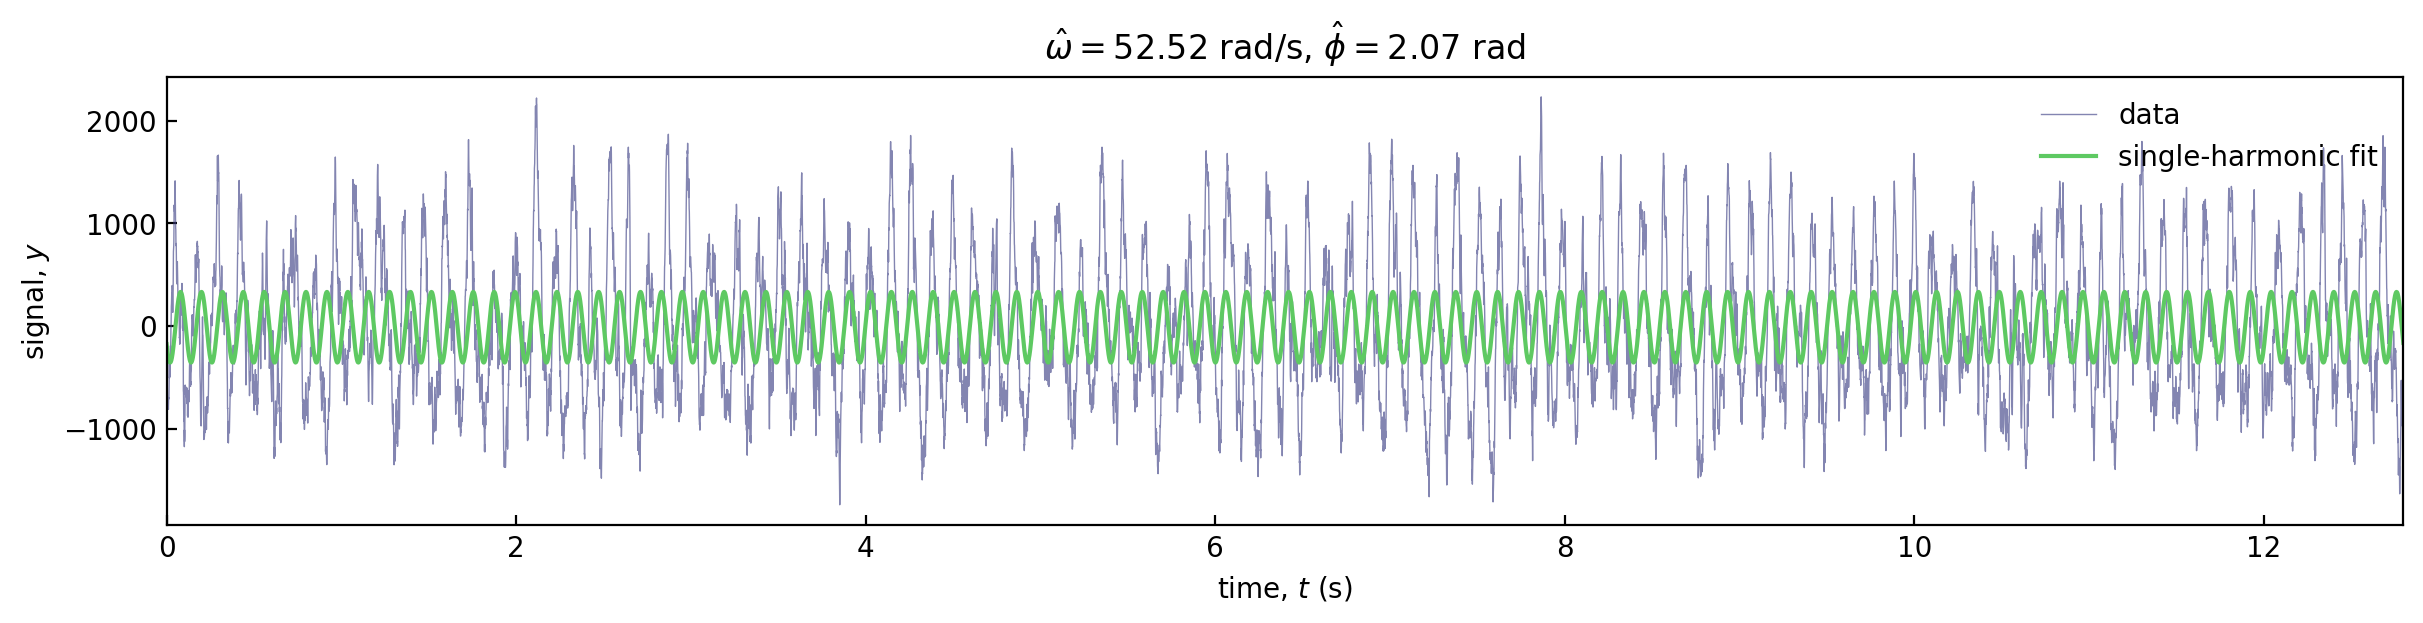

In [13]:
fig, ax = plt.subplots(figsize=(12, 3), constrained_layout=True)
ax.plot(tk, yk, color=cmap(0.2), lw=0.5, alpha=0.65, label='data')
ax.plot(tk, fitted_signal, color=cmap(0.75), lw=1.5, label='single-harmonic fit')

ax.set(
    xlabel='time, $t$ (s)',
    ylabel='signal, $y$',
    title=rf'$\hat{{\omega}}={omega_hat:.2f}$ rad/s, $\hat{{\phi}}={phi_hat:.2f}$ rad',
    xlim=(tk[0], tk[-1]),
)
ax.tick_params(direction='in')
ax.legend(frameon=False)
plt.show()

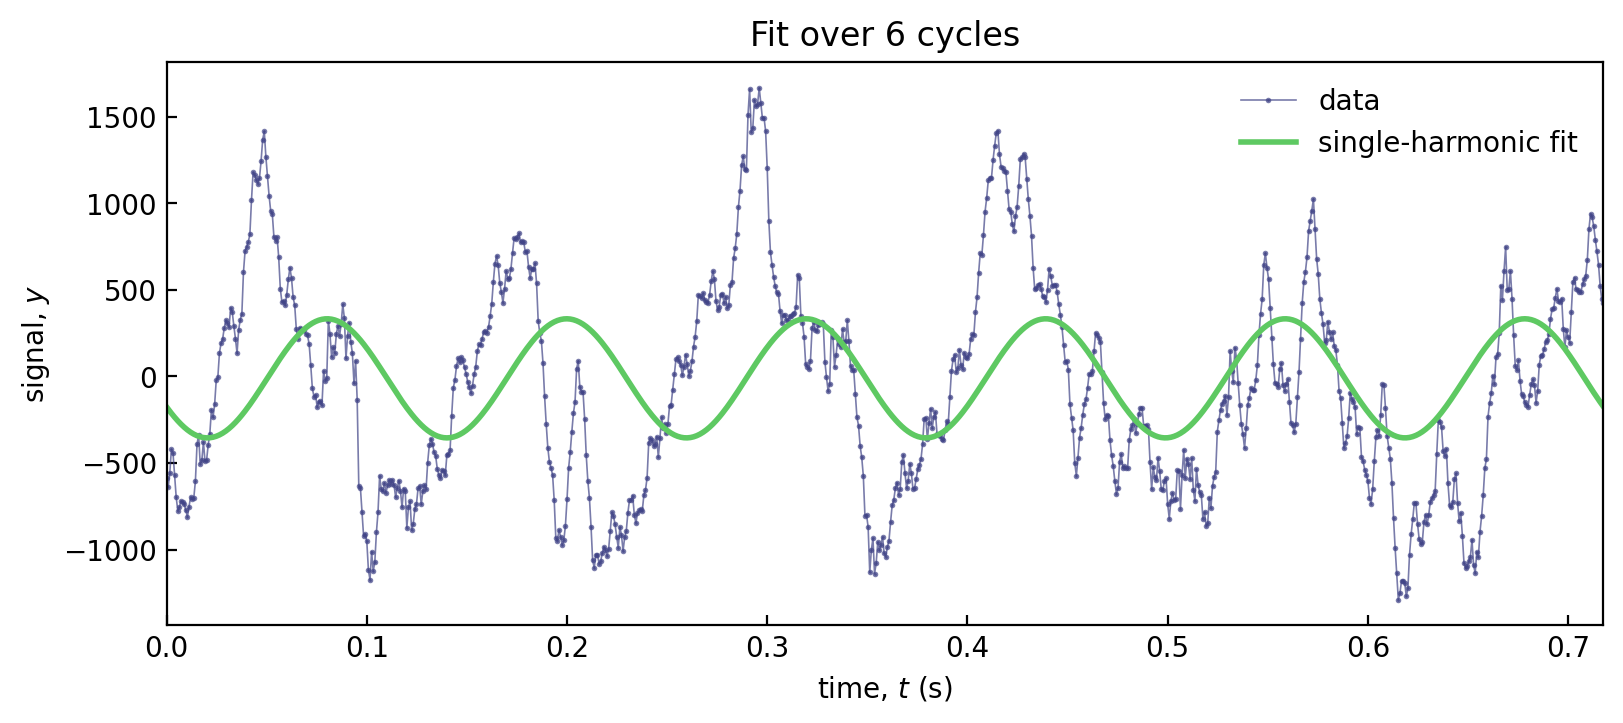

In [15]:
n_cycles = 6
period_hat = 2 * np.pi / omega_hat
narrow_window = tk <= tk[0] + n_cycles * period_hat

fig, ax = plt.subplots(figsize=(8, 3.5), constrained_layout=True)
ax.plot(
    tk[narrow_window],
    yk[narrow_window],
    '.-',
    color=cmap(0.2),
    lw=0.6,
    ms=2,
    alpha=0.7,
    label='data',
)
ax.plot(
    tk[narrow_window],
    fitted_signal[narrow_window],
    color=cmap(0.75),
    lw=2,
    label='single-harmonic fit',
)

ax.set(
    xlabel='time, $t$ (s)',
    ylabel='signal, $y$',
    title=f'Fit over {n_cycles} cycles',
    xlim=(tk[narrow_window][0], tk[narrow_window][-1]),
)
ax.tick_params(direction='in')
ax.legend(frameon=False)
plt.show()

## Hilbert-transform phase

For a real signal $y(t)$, the Hilbert transform supplies a quadrature component $\mathcal{H}[y](t)$. Together they form the **analytic signal**

$$z(t)=y(t)+i\mathcal{H}[y](t)=A(t)e^{i\theta_H(t)},$$

whose argument $\theta_H(t)=\arg z(t)$ is the instantaneous phase. This phase is most meaningful for a narrowband signal, so the EEG is first isolated in the 4–12 Hz theta band with a zero-phase filter. Subtracting the uniform phase advance $\hat\omega t$ gives the relative phase

$$\phi_H(t)=\operatorname{wrap}\!\left[\theta_H(t)-\hat\omega t\right],$$

where `wrap` maps angles to $[-\pi,\pi)$.

In [16]:
from scipy.signal import butter, hilbert, sosfiltfilt

theta_band = (4.0, 12.0)  # Hz
theta_filter = butter(
    4,
    theta_band,
    btype='bandpass',
    fs=sampling_frequency,
    output='sos',
)
theta_signal = sosfiltfilt(theta_filter, centered_signal)
analytic_signal = hilbert(theta_signal)

hilbert_phase = np.unwrap(np.angle(analytic_signal))
relative_phase_unwrapped = hilbert_phase - omega_hat * tk
relative_phase = np.angle(np.exp(1j * relative_phase_unwrapped))

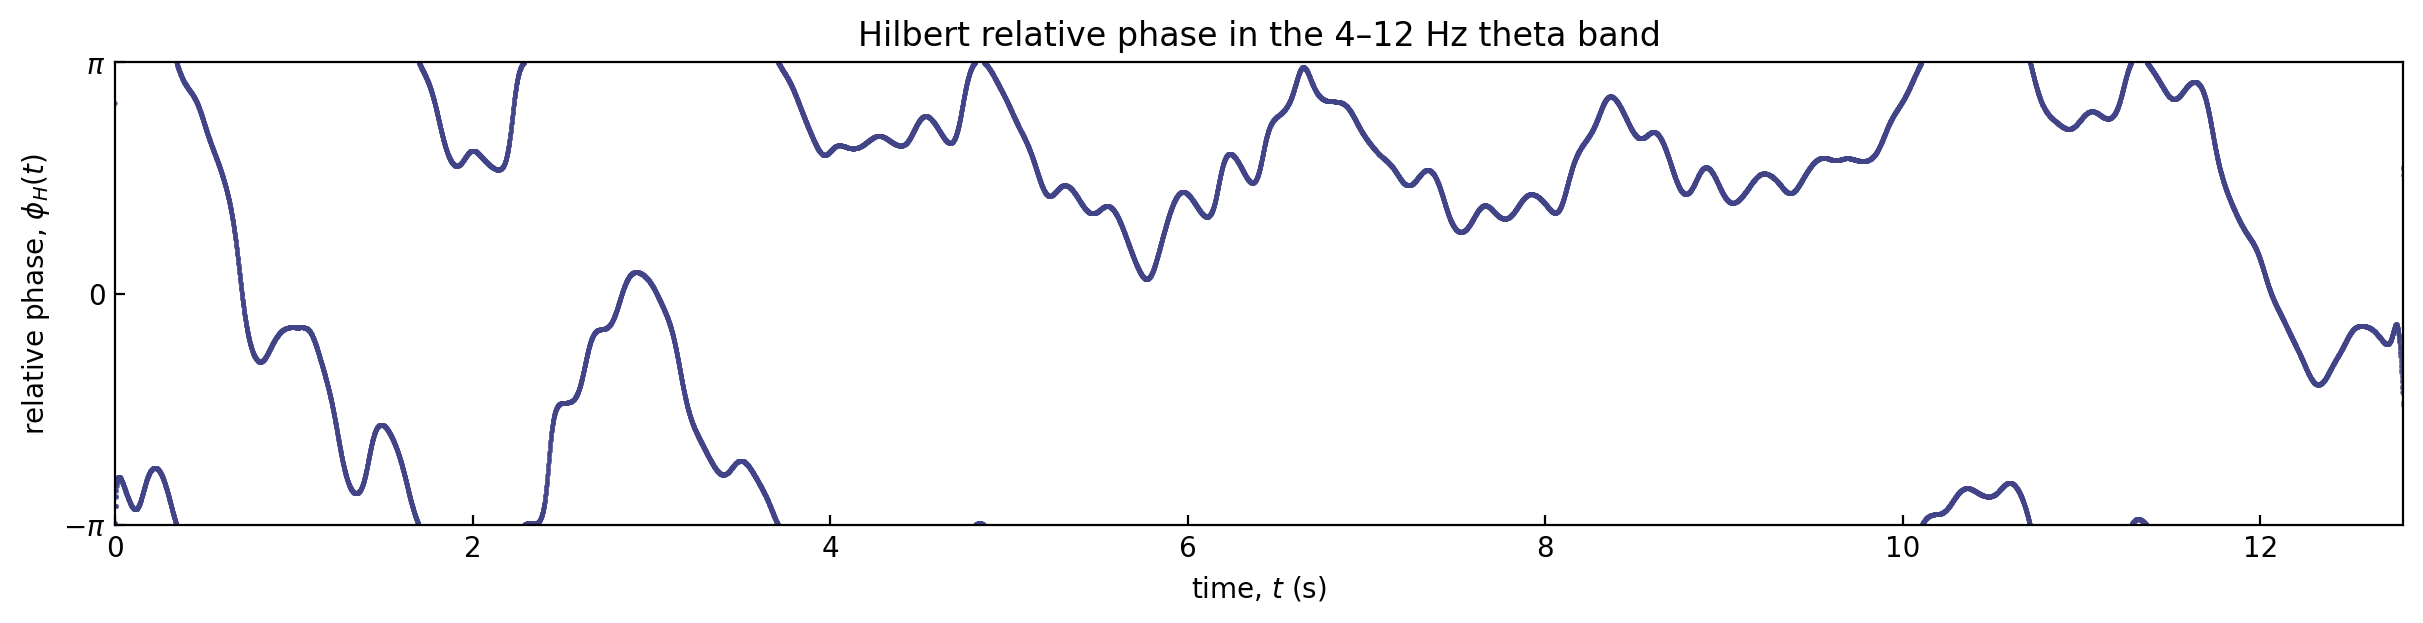

In [17]:
fig, ax = plt.subplots(figsize=(12, 3), constrained_layout=True)
ax.plot(tk, relative_phase, '.', color=cmap(0.2), ms=1.5, alpha=0.7)

ax.set(
    xlabel='time, $t$ (s)',
    ylabel=r'relative phase, $\phi_H(t)$',
    title='Hilbert relative phase in the 4–12 Hz theta band',
    xlim=(tk[0], tk[-1]),
    ylim=(-np.pi, np.pi),
    yticks=(-np.pi, 0, np.pi),
    yticklabels=(r'$-\pi$', '0', r'$\pi$'),
)
ax.tick_params(direction='in')
plt.show()

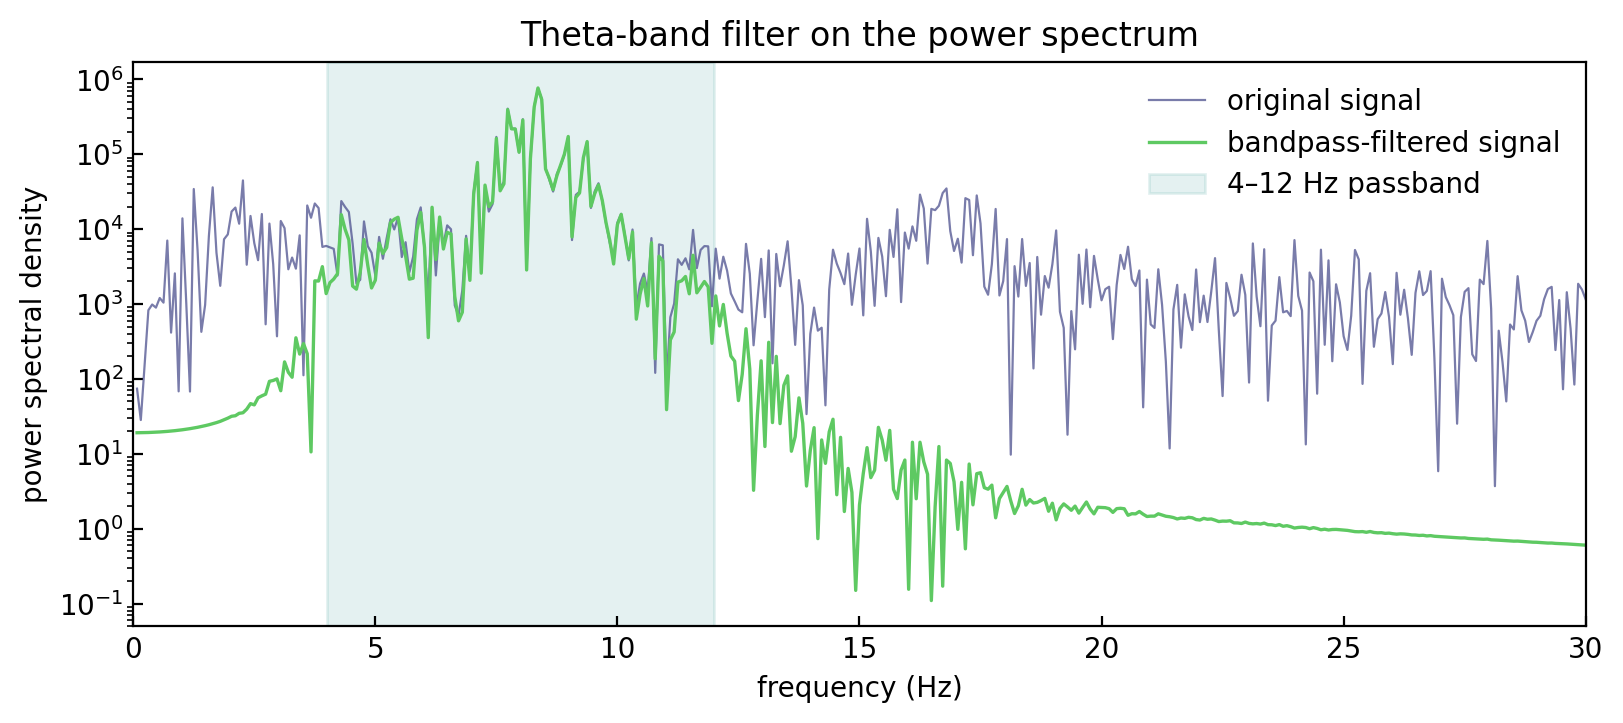

In [18]:
filtered_fft_values = np.fft.rfft(theta_signal)
filtered_power_spectrum = (
    np.abs(filtered_fft_values) ** 2 / (sampling_frequency * theta_signal.size)
)
filtered_power_spectrum[1:-1] *= 2

fig, ax = plt.subplots(figsize=(8, 3.5), constrained_layout=True)
spectrum_window = (frequencies > 0) & (frequencies <= 30)
ax.semilogy(
    frequencies[spectrum_window],
    power_spectrum[spectrum_window],
    color=cmap(0.2),
    lw=0.8,
    alpha=0.7,
    label='original signal',
)
ax.semilogy(
    frequencies[spectrum_window],
    filtered_power_spectrum[spectrum_window],
    color=cmap(0.75),
    lw=1.2,
    label='bandpass-filtered signal',
)
ax.axvspan(*theta_band, color=cmap(0.5), alpha=0.12, label='4–12 Hz passband')

ax.set(
    xlabel='frequency (Hz)',
    ylabel='power spectral density',
    title='Theta-band filter on the power spectrum',
    xlim=(0, 30),
)
ax.tick_params(direction='in')
ax.legend(frameon=False)
plt.show()

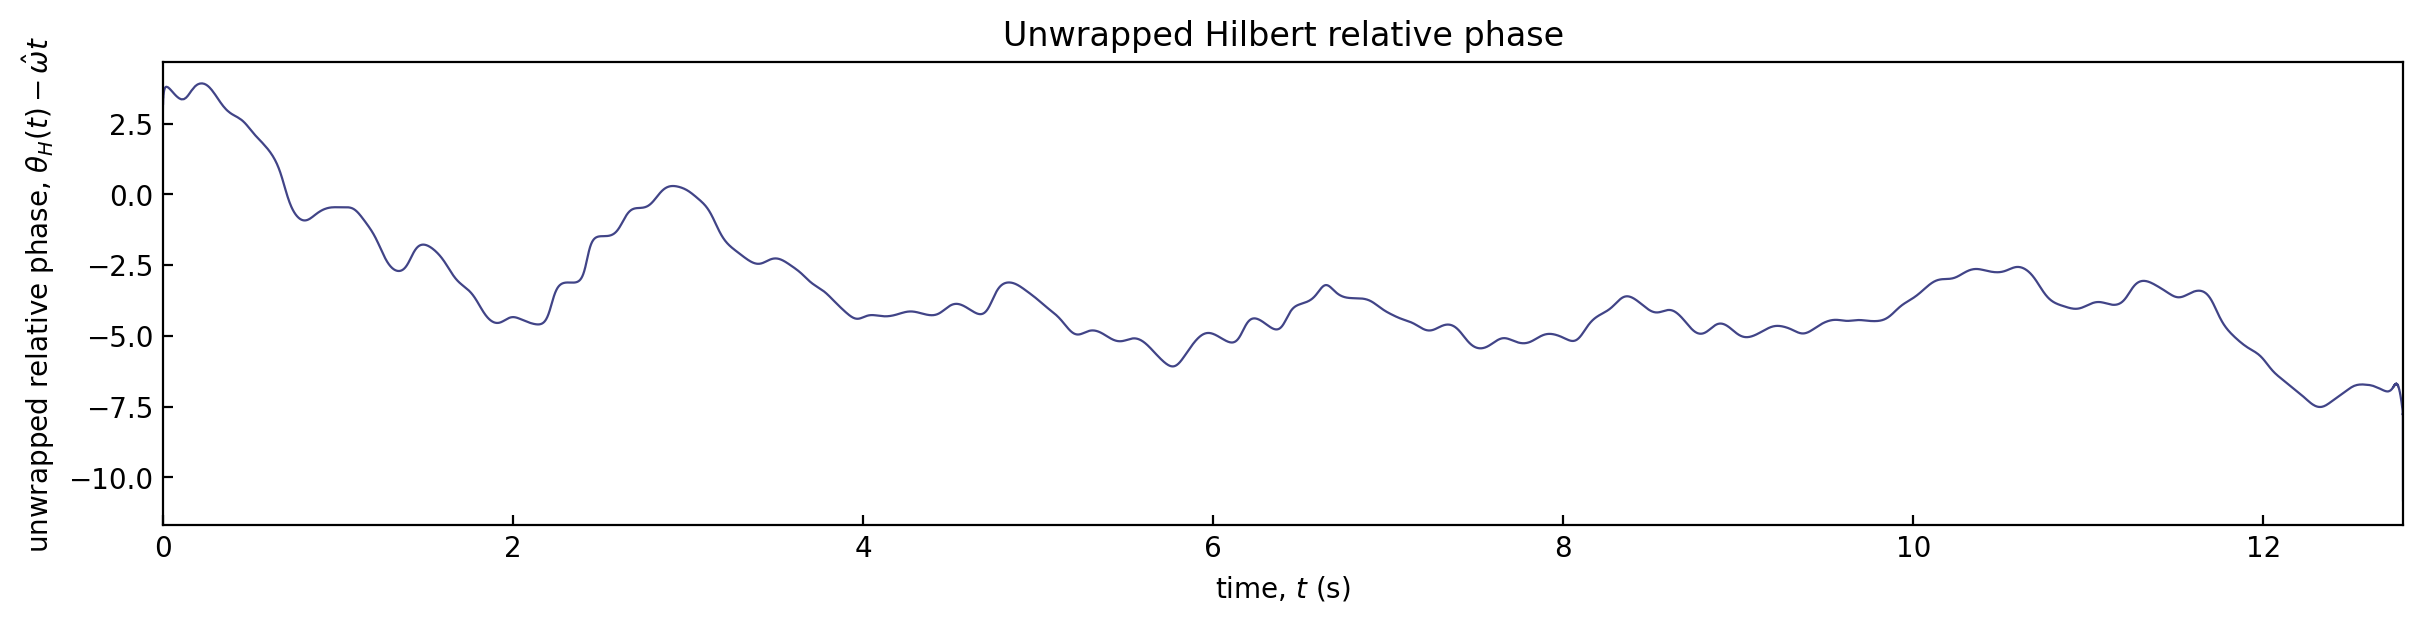

In [19]:
fig, ax = plt.subplots(figsize=(12, 3), constrained_layout=True)
ax.plot(tk, relative_phase_unwrapped, color=cmap(0.2), lw=0.8)

ax.set(
    xlabel='time, $t$ (s)',
    ylabel=r'unwrapped relative phase, $\theta_H(t)-\hat{\omega}t$',
    title='Unwrapped Hilbert relative phase',
    xlim=(tk[0], tk[-1]),
)
ax.tick_params(direction='in')
plt.show()

## Comparison to Our Method

The saved Bayesian result is evaluated on every fourth sample of the original trace and reports the posterior mean and interquartile interval of the unwrapped relative phase. Because the latent phase and Hilbert phase have arbitrary phase origins, the Hilbert curve is shifted by one constant estimated over the central 90% of the record. This alignment changes only the phase origin, not the time-dependent phase fluctuations.

In [ ]:
inference_path = '../Hippocampal/data/phi_inf_data_good.npz'
with np.load(inference_path) as inference_data:
    inference_time = inference_data['tk']
    inferred_phase_mean = inference_data['phi_inf_mean']
    inferred_phase_lo = inference_data['phi_inf_lo']
    inferred_phase_hi = inference_data['phi_inf_hi']

hilbert_phase_on_inference_grid = np.interp(
    inference_time, tk, relative_phase_unwrapped
)

# Align the arbitrary phase origins away from filter-edge transients.
edge_samples = int(0.05 * inference_time.size)
interior = slice(edge_samples, -edge_samples)
phase_origin_shift = np.mean(
    inferred_phase_mean[interior] - hilbert_phase_on_inference_grid[interior]
)
hilbert_phase_aligned = hilbert_phase_on_inference_grid + phase_origin_shift

print(f'Phase-origin shift applied to Hilbert estimate: {phase_origin_shift:.3f} rad')

In [ ]:
fig, ax = plt.subplots(figsize=(12, 3.5), constrained_layout=True)
ax.fill_between(
    inference_time,
    inferred_phase_lo,
    inferred_phase_hi,
    color=cmap(0.2),
    alpha=0.18,
    label='our method: interquartile interval',
)
ax.plot(
    inference_time,
    inferred_phase_mean,
    color=cmap(0.2),
    lw=1.2,
    label='our method: posterior mean',
)
ax.plot(
    inference_time,
    hilbert_phase_aligned,
    color=cmap(0.75),
    lw=0.9,
    alpha=0.9,
    label='Hilbert phase',
)

ax.set(
    xlabel='time, $t$ (s)',
    ylabel=r'unwrapped relative phase, $\phi(t)$',
    title='Relative-phase comparison',
    xlim=(inference_time[0], inference_time[-1]),
)
ax.tick_params(direction='in')
ax.legend(frameon=False, ncol=3)
plt.show()